In [1]:
!pip install roboflow ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 19.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 30.6 MB/s  0:00:00
  Attempting uninstall: typer
    Found existing installation: typer 0.27.3
    Uninstalling typer-0.27.3:
      Successfully uninstalled typer-0.27.3
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [ultralytics]


In [2]:
from roboflow import Roboflow
rf = Roboflow(api_key="gKtiNUGNazhMELNWgu8o")
project = rf.workspace("alfadhul-almubarak").project("bahraini-dishes")
version = project.version(2)
dataset = version.download("yolo26")

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to Bahraini-Dishes-2 in yolo26:: 100%|██████████| 2095/2095 [00:00<00:00, 3560.59it/s]


In [3]:
from ultralytics import YOLO
model = YOLO("yolo26s.pt")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


In [4]:
model.train(data='/content/Bahraini-Dishes-2/data.yaml', epochs=15)

Ultralytics 8.4.202 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/Bahraini-Dishes-2/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=15, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=None, opset=None, optimize=False, 

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2, 3, 4, 5, 6, 7, 8])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7a4d627bbdd0>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.0470

In [5]:
finetuned_model = YOLO('/content/runs/detect/train/weights/best.pt')

In [6]:
results = finetuned_model('/content/Bahraini-Dishes-2/test/images/4324324_jpeg.rf.5706692ee920704d6fd96ed1e40c3ebf.jpg')


image 1/1 /content/Bahraini-Dishes-2/test/images/4324324_jpeg.rf.5706692ee920704d6fd96ed1e40c3ebf.jpg: 640x640 1 Luqaimat, 17.7ms
Speed: 3.5ms preprocess, 17.7ms inference, 1.8ms postprocess per image at shape (1, 3, 640, 640)


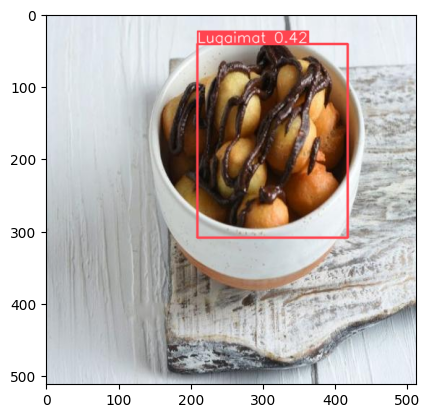

In [7]:
import matplotlib.pyplot as plt
plt.imshow(results[0].plot()[..., ::-1]);

In [8]:
metrics = model.val(data='/content/Bahraini-Dishes-2/data.yaml', split='test', plots=True)

print(metrics.box.mp, metrics.box.mr, metrics.box.map50, metrics.box.map)
print(metrics.save_dir)

Ultralytics 8.4.202 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26s summary (fused): 120 layers, 9,469,050 parameters, 0 gradients, 20.8 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 891.2±195.1 MB/s, size: 41.4 KB)
val: Scanning /content/Bahraini-Dishes-2/test/labels... 33 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 33/33 1.7Kit/s 0.0s
val: New cache created: /content/Bahraini-Dishes-2/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 1.5it/s 2.1s
                   all         33        117      0.774      0.676        0.8      0.585
                Aseeda          3          3      0.734      0.667      0.789      0.607
              Balaleet          5          5      0.951        0.8      0.962      0.636
          Bayd w Tamat          2          2          1      0.722      0.995      0.795
                 Halwa          5          6      0.808      0.708  

In [9]:
from glob import glob
import pandas as pd

best_model = YOLO('/content/runs/detect/train/weights/best.pt')

rows = []
for image_path in glob('/content/Bahraini-Dishes-2/test/images/*'):
    label_path = image_path.replace('/images/', '/labels/').rsplit('.', 1)[0] + '.txt'
    first_line = open(label_path).readline()
    if first_line == "":
        continue                                      # image with no label
    true_class = int(first_line.split()[0])

    result = best_model(image_path, verbose=False)[0]
    if len(result.boxes) == 0:
        continue                                      # the model found nothing, so skip this image
    best_box = result.boxes[result.boxes.conf.argmax()]
    predicted_class = int(best_box.cls)

    if predicted_class != true_class:
        rows.append([image_path, best_model.names[predicted_class], best_model.names[true_class], float(best_box.conf)])

mistakes = pd.DataFrame(rows, columns=["image", "predicted", "actual", "confidence"])
mistakes.sort_values("confidence", ascending=False).head(10)

,image,predicted,actual,confidence
2,/content/Bahraini-Dishes-2/test/images/images-...,Harees,Halwa,0.781746
1,/content/Bahraini-Dishes-2/test/images/images-...,Harees,Aseeda,0.496768
0,/content/Bahraini-Dishes-2/test/images/2f73e8c...,Harees,Balaleet,0.441343
3,/content/Bahraini-Dishes-2/test/images/images-...,Aseeda,Bayd w Tamat,0.401854
